# Rol 2 — Arquitecto de Segmentación por Partición
**Proyecto Retador: Patrones Invisibles — Información, Incertidumbre y Movilidad Urbana**
ML No Supervisado · Universidad de La Sabana · 2026-II

**Preguntas de negocio para UrbanMove**
1. ¿En qué **macro-zonas** se organiza realmente la demanda de recogida, para posicionar conductores?
2. ¿Qué **zonas** y qué **viajes** son atípicos (ruido) y cómo deben tratarse operativamente?

**Diseño del análisis**

| Parte | Qué se segmenta | Métodos | Validación / hiperparámetros |
|---|---|---|---|
| A | Puntos de **recogida** (50 000) | K-means, jerárquico aglomerativo (Ward y otros enlaces), DBSCAN | Codo, silueta, Davies-Bouldin, Calinski-Harabasz, ARI entre métodos, gráfica k-distancia para ε |
| B | **Viajes** en el espacio (log distancia, log duración) | DBSCAN (+ comparación con K-means) | k-distancia, % de ruido, perfil de los viajes ruidosos |

**Decisión metodológica clave — distancia.** Latitud y longitud **no** se usan como coordenadas euclidianas (1° de longitud ≈ 84 km y 1° de latitud ≈ 111 km en NYC). Para K-means y el jerárquico proyectamos a **km** con una proyección equirectangular local centrada en Midtown (error < 0.5 % dentro de la ciudad, ver `utils.a_km`); para DBSCAN usamos directamente la **métrica haversine** sobre radianes.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import utils
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
SEED = utils.SEMILLA; R_M = utils.R_TIERRA_KM * 1000

df = utils.cargar_muestra()
X = df[["px", "py"]].values            # recogida en km (x = este, y = norte)
print(df.shape); print(df[["px", "py"]].describe().round(2))

(50000, 25)
             px        py
count  50000.00  50000.00
mean       0.54      0.13
std        3.14      3.07
min       -8.66    -17.14
25%       -0.99     -1.37
50%       -0.15      0.49
75%        1.06      2.05
max       21.12     15.89


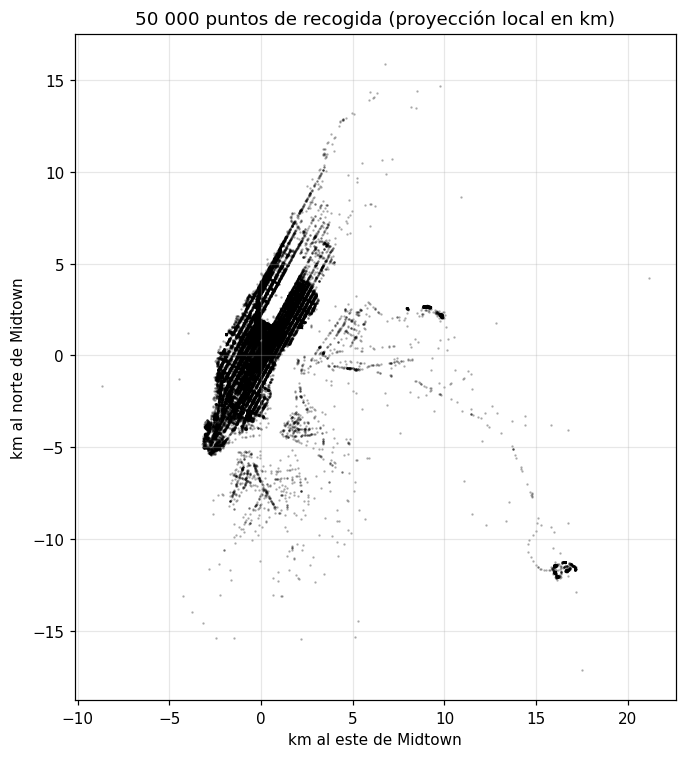

In [2]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(df.px, df.py, s=.3, alpha=.3, c="k")
ax.set_xlabel("km al este de Midtown"); ax.set_ylabel("km al norte de Midtown"); ax.set_aspect("equal")
ax.set_title("50 000 puntos de recogida (proyección local en km)")
plt.tight_layout(); plt.show()

## Parte A — Segmentación espacial de la demanda de recogida
### A.1 K-means: selección de K con método del codo y silueta
Probamos $K = 2,\dots,15$ con `n_init=10` (10 inicializaciones k-means++ por K, se conserva la de menor inercia). La silueta se calcula sobre una submuestra aleatoria de 10 000 puntos (su costo es $O(n^2)$). El codo se localiza objetivamente con el criterio de **máxima distancia a la cuerda** (*kneedle*) sobre la curva de inercia normalizada.

In [3]:
Ks = range(2, 16); filas = []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    filas.append([k, km.inertia_, silhouette_score(X, km.labels_, sample_size=10000, random_state=0),
                  davies_bouldin_score(X, km.labels_), calinski_harabasz_score(X, km.labels_)])
curva = pd.DataFrame(filas, columns=["K", "inercia", "silueta", "davies_bouldin", "calinski_harabasz"]).set_index("K")
curva["caída inercia %"] = -100 * curva.inercia.pct_change()

def kneedle(x, y):  # punto de máxima distancia a la recta entre extremos (curva decreciente convexa)
    x = (np.asarray(x) - min(x)) / (max(x) - min(x)); y = (np.asarray(y) - min(y)) / (max(y) - min(y))
    return int(np.argmax((1 - x) - y))
def kneedle_creciente(y):  # curva creciente y convexa (k-distancia ordenada): punto más alejado bajo la diagonal
    y = np.asarray(y, float); x = np.linspace(0, 1, len(y)); yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(x - yn))
K_codo = list(Ks)[kneedle(list(Ks), curva.inercia.values)]
print(curva.round(3).to_string()); print("\nCodo (kneedle):", K_codo)

       inercia  silueta  davies_bouldin  calinski_harabasz  caída inercia %
K                                                                          
2   545897.234    0.808           0.178          38411.674              NaN
3   284024.176    0.458           0.595          59962.951           47.971
4   188168.797    0.491           0.504          68826.611           33.749
5   124138.595    0.447           0.563          84691.785           34.028
6    98269.573    0.402           0.650          88220.358           20.839
7    84566.158    0.400           0.687          86777.427           13.945
8    73120.138    0.396           0.726          87146.055           13.535
9    63403.782    0.411           0.691          88888.299           13.288
10   55861.449    0.382           0.724          90436.681           11.896
11   49496.346    0.394           0.723          92493.801           11.394
12   44627.938    0.405           0.701          93751.951            9.836
13   41223.9

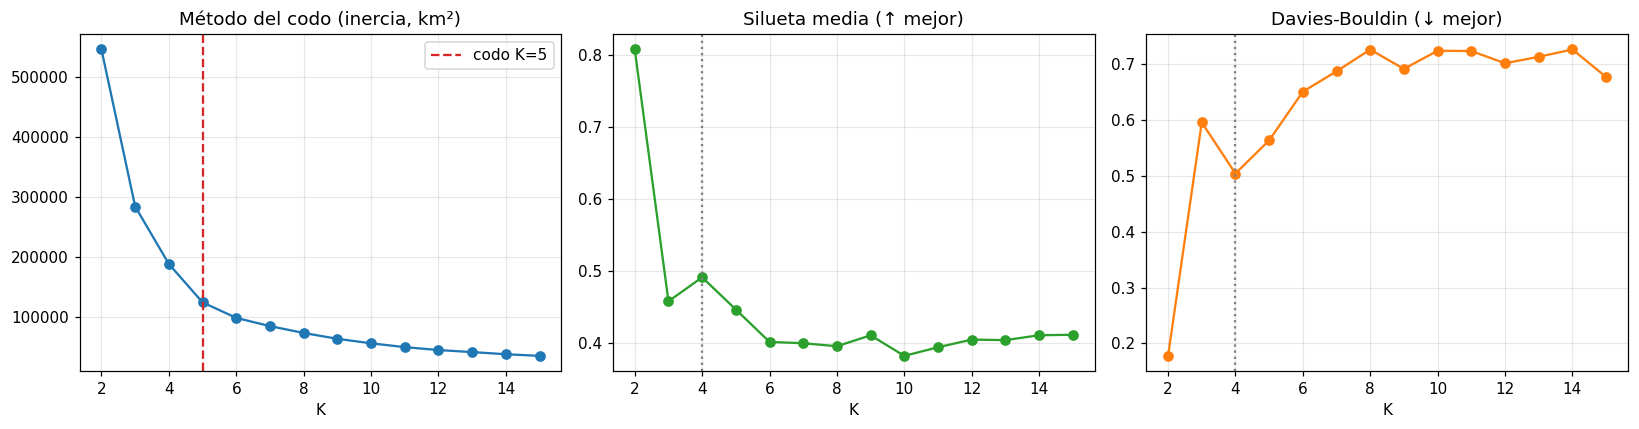

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(curva.index, curva.inercia, "o-"); axs[0].axvline(K_codo, ls="--", c="C3", label=f"codo K={K_codo}")
axs[0].set_title("Método del codo (inercia, km²)"); axs[0].set_xlabel("K"); axs[0].legend()
axs[1].plot(curva.index, curva.silueta, "o-", c="C2"); axs[1].set_title("Silueta media (↑ mejor)"); axs[1].set_xlabel("K")
axs[2].plot(curva.index, curva.davies_bouldin, "o-", c="C1"); axs[2].set_title("Davies-Bouldin (↓ mejor)"); axs[2].set_xlabel("K")
for a in axs[1:]: a.axvline(4, ls=":", c="gray")
plt.tight_layout(); plt.savefig("figuras/rol2_seleccion_K.png", bbox_inches="tight"); plt.show()

**Justificación de K (con nuestros números).**
- **K = 2** tiene la silueta más alta, pero es una partición **trivial**: separa la zona de JFK del resto de la ciudad (un grupo del 2 % de los datos a ~20 km del centro). Con esa brecha geográfica cualquier partición que la aísle tendrá silueta alta; no aporta ninguna decisión de posicionamiento dentro de Manhattan.
- Entre $K\ge3$, **K = 4** maximiza la silueta (**0.491**) y minimiza Davies-Bouldin (**0.504**).
- El codo objetivo (kneedle) está en **K = 5**: la caída de inercia es ~34 % al pasar a K = 4 y a K = 5, y cae a 21 % en K = 6 y 14 % en K = 7. Pero pasar de 4 a 5 empeora la silueta (0.491 → 0.447) y Davies-Bouldin (0.504 → 0.563): el quinto cluster parte una región densa en lugar de separar grupos reales.
- Por tanto **elegimos K = 4**: está en la zona del codo y es el mejor K no trivial por las dos métricas de validación.

In [5]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
df["km"] = km.labels_
# Reordenar etiquetas por tamaño para lectura estable
orden = df.km.value_counts().index; mapa = {c: i for i, c in enumerate(orden)}; df["km"] = df.km.map(mapa)
cent = df.groupby("km")[["pickup_latitude", "pickup_longitude", "px", "py"]].mean()

perfil_km = df.groupby("km").agg(viajes=("id", "size"), lat=("pickup_latitude", "mean"), lon=("pickup_longitude", "mean"),
                                 dist_mediana_km=("dist_km", "median"), dur_mediana_min=("duracion_min", "median"),
                                 vel_media_kmh=("vel_kmh", "mean"), pct_fds=("fin_de_semana", "mean"),
                                 zona_grid_principal=("zona_pickup", lambda s: s.value_counts().index[0]))
perfil_km["% viajes"] = 100 * perfil_km.viajes / len(df)
print(perfil_km.round(3).to_string())

    viajes     lat     lon  dist_mediana_km  dur_mediana_min  vel_media_kmh  pct_fds       zona_grid_principal  % viajes
km                                                                                                                      
0    25467  40.770 -73.971            1.960           10.133         14.057    0.258   Z03 Upper East Side Sur    50.934
1    21878  40.734 -73.993            2.084           11.200         13.780    0.318      Z01 Chelsea/Flatiron    43.756
2     1599  40.770 -73.874            9.284           25.050         21.039    0.236  Z12 Aeropuerto LaGuardia     3.198
3     1056  40.646 -73.785           19.616           38.958         28.470    0.268        Z15 Aeropuerto JFK     2.112


**Lectura de las 4 macro-zonas (K-means).**

| Cluster | Qué es | % recogidas | Distancia mediana | Duración mediana |
|---|---|---|---|---|
| C0 | Manhattan **norte-centro** (Midtown Este, Upper East/West Side) | 50.9 % | 1.96 km | 10.1 min |
| C1 | Manhattan **sur-centro** (Midtown Oeste, Chelsea, Village, Downtown) + Brooklyn cercano | 43.8 % | 2.08 km | 11.2 min |
| C2 | **LaGuardia** y Queens norte | 3.2 % | 9.28 km | 25.1 min |
| C3 | **JFK** | 2.1 % | 19.6 km | 39.0 min |

Dos macro-zonas absorben el 94.7 % de las recogidas con viajes cortos (~2 km); las dos zonas aeroportuarias, con solo el 5.3 % de las recogidas, producen viajes **4.5 a 9.5 veces más largos**: un conductor en JFK queda ocupado ~39 min por viaje. C1 tiene más peso de fin de semana (31.8 % vs 25.8 % en C0): es la zona de ocio (Village, LES).

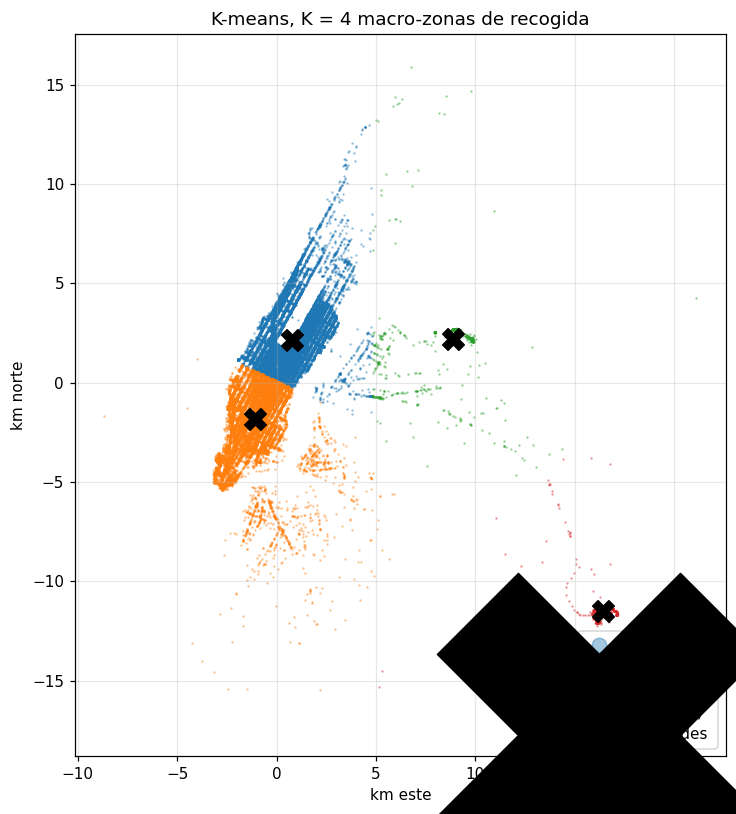

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
pal = sns.color_palette("tab10", K)
for c in range(K):
    m = df.km == c; ax.scatter(df.px[m], df.py[m], s=.4, alpha=.4, color=pal[c], label=f"C{c} ({m.mean():.1%})")
ax.scatter(cent.px, cent.py, marker="X", s=200, c="k", label="centroides")
ax.set_aspect("equal"); ax.legend(markerscale=15, loc="lower right"); ax.set_title("K-means, K = 4 macro-zonas de recogida")
ax.set_xlabel("km este"); ax.set_ylabel("km norte"); plt.tight_layout(); plt.savefig("figuras/rol2_kmeans.png", bbox_inches="tight"); plt.show()

### A.2 Clustering jerárquico aglomerativo
El jerárquico requiere la matriz de distancias ($O(n^2)$ memoria: 50 000² ≈ 20 GB), así que se ajusta sobre una **submuestra aleatoria de 5 000 recogidas** y se comparan cuatro criterios de enlace. En el dendrograma de Ward, el rango de alturas en el que un corte horizontal produce K clusters (el “salto”) indica qué tan estable es esa partición.

In [7]:
rs = np.random.default_rng(SEED); sub = rs.choice(len(df), 5000, replace=False)
Xs = X[sub]; km_sub = df.km.values[sub]
filas = []; Z = {}
for metodo in ["ward", "complete", "average", "single"]:
    t = time.time(); Z[metodo] = linkage(Xs, method=metodo)
    lab = fcluster(Z[metodo], t=K, criterion="maxclust")
    tam = np.bincount(lab)[1:]
    filas.append([metodo, silhouette_score(Xs, lab), davies_bouldin_score(Xs, lab), calinski_harabasz_score(Xs, lab),
                  adjusted_rand_score(km_sub, lab), sorted(tam, reverse=True), time.time() - t])
tabla_jer = pd.DataFrame(filas, columns=["enlace", "silueta", "davies_bouldin", "calinski_harabasz", "ARI vs K-means", "tamaños", "seg"])
print(tabla_jer.round(3).to_string(index=False))

  enlace  silueta  davies_bouldin  calinski_harabasz  ARI vs K-means                tamaños   seg
    ward    0.483           0.481           6967.382           0.822 [2792, 1959, 133, 116] 0.921
complete    0.291           0.577           2353.113           0.064   [4524, 257, 120, 99] 0.898
 average    0.683           0.204           1506.513           0.079      [4877, 120, 2, 1] 0.914
  single    0.698           0.296           1496.742           0.078      [4879, 116, 4, 1] 0.592


**Comparación de enlaces.** *Average* y *single* obtienen la silueta más alta (0.68–0.70) pero son particiones **degeneradas**: un cluster con el 97.5 % de los puntos y grupos de 1–2 puntos (efecto *chaining*). Esto muestra que **la silueta sola no basta** para elegir un método: hay que mirar los tamaños y el sentido operativo. **Ward** produce grupos equilibrados, silueta 0.483 y coincide fuertemente con K-means (**ARI = 0.822**), lo cual es esperable: ambos minimizan varianza intra-cluster.

Alturas de las últimas 8 fusiones (Ward): [305.  223.3 138.3 104.   77.2  54.5  52.9  45.2]
Rango de alturas donde el corte produce K clusters (salto): {2: np.float64(81.7), 3: np.float64(85.0), 4: np.float64(34.2), 5: np.float64(26.8), 6: np.float64(22.8), 7: np.float64(1.6), 8: np.float64(7.7), 9: np.float64(0.4)}


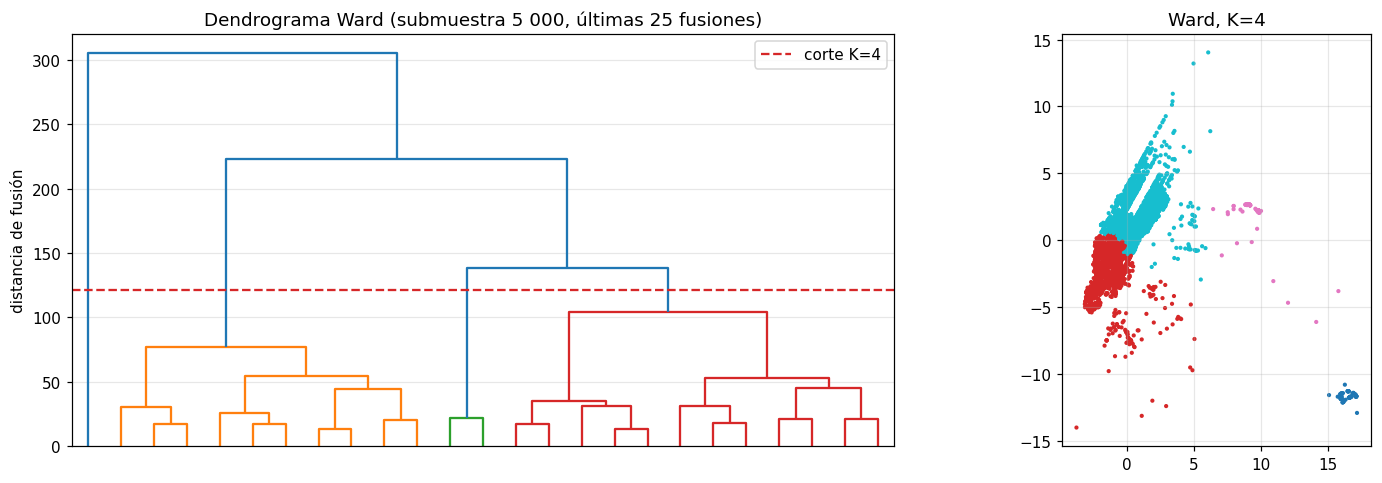

In [8]:
alturas = Z["ward"][::-1, 2]           # alturas de fusión de la última hacia atrás
saltos = -np.diff(alturas[:10])
print("Alturas de las últimas 8 fusiones (Ward):", alturas[:8].round(1))
print("Rango de alturas donde el corte produce K clusters (salto):", {k + 2: round(s, 1) for k, s in enumerate(saltos[:8])})
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
dendrogram(Z["ward"], truncate_mode="lastp", p=25, ax=axs[0], color_threshold=(alturas[K - 2] + alturas[K - 1]) / 2, no_labels=True)
axs[0].axhline((alturas[K - 2] + alturas[K - 1]) / 2, c="C3", ls="--", label="corte K=4"); axs[0].legend()
axs[0].set_title("Dendrograma Ward (submuestra 5 000, últimas 25 fusiones)"); axs[0].set_ylabel("distancia de fusión")
lab_w = fcluster(Z["ward"], t=K, criterion="maxclust")
axs[1].scatter(Xs[:, 0], Xs[:, 1], c=lab_w, cmap="tab10", s=3); axs[1].set_aspect("equal"); axs[1].set_title("Ward, K=4")
plt.tight_layout(); plt.savefig("figuras/rol2_jerarquico.png", bbox_inches="tight"); plt.show()

**Lectura del dendrograma.** Los mayores rangos de corte están en K = 2 (81.7) y K = 3 (85.0): son las separaciones de los aeropuertos, las más evidentes. El rango para K = 4 (34.2) es aún mayor que el de K = 5 (26.8) y K = 6 (22.8), y en K = 7 colapsa a 1.6: **más allá de 6 grupos las particiones son inestables**. K = 4 es por tanto consistente con el dendrograma, con la silueta y con K-means.

### A.3 DBSCAN con métrica haversine
**Hiperparámetros.**
- `min_samples = 50`: una zona densa debe tener al menos 50 recogidas en su vecindario (0.1 % de la muestra ≈ 29 viajes/día en el dataset completo de 1.44 M viajes en 182 días). Es un umbral de **viabilidad operativa**: por debajo de eso no compensa posicionar un conductor.
- `ε`: se toma del **codo de la gráfica k-distancia** (distancia al 50.º vecino más cercano, ordenada), localizado con kneedle.

Codo de la k-distancia: percentil 97.2 -> eps ≈ 490 m
Percentiles de la distancia al 50º vecino (m): {50: 74, 75: 102, 90: 156, 95: 284, 97: 468, 99: 1008}


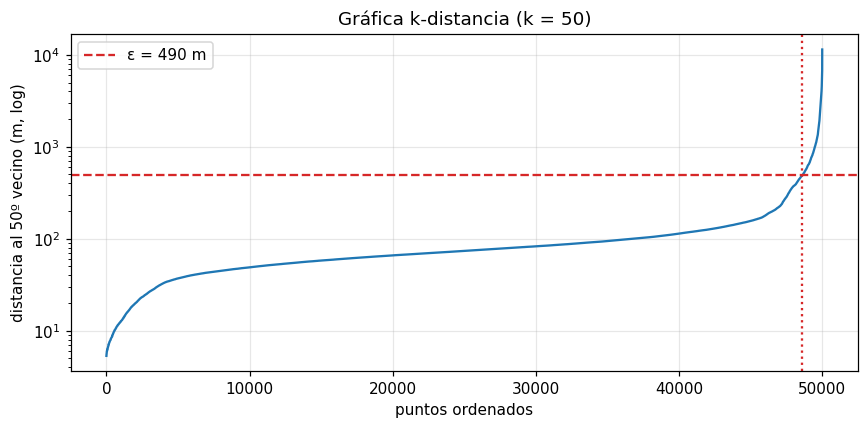

In [9]:
MIN_S = 50
Rad = np.radians(df[["pickup_latitude", "pickup_longitude"]].values)
nn = NearestNeighbors(n_neighbors=MIN_S, metric="haversine", algorithm="ball_tree").fit(Rad)
dist_k, _ = nn.kneighbors(Rad)
kdist = np.sort(dist_k[:, -1]) * R_M                     # metros
i_codo = kneedle_creciente(kdist)
EPS_M = float(np.round(kdist[i_codo], -1))
print(f"Codo de la k-distancia: percentil {100 * i_codo / len(kdist):.1f} -> eps ≈ {EPS_M:.0f} m")
print("Percentiles de la distancia al 50º vecino (m):", {q: round(np.percentile(kdist, q)) for q in [50, 75, 90, 95, 97, 99]})
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kdist); ax.axhline(EPS_M, c="C3", ls="--", label=f"ε = {EPS_M:.0f} m"); ax.axvline(i_codo, c="C3", ls=":")
ax.set_yscale("log"); ax.set_xlabel("puntos ordenados"); ax.set_ylabel("distancia al 50º vecino (m, log)")
ax.set_title("Gráfica k-distancia (k = 50)"); ax.legend(); plt.tight_layout(); plt.savefig("figuras/rol2_kdistancia.png", bbox_inches="tight"); plt.show()

**ε elegido.** El codo de la k-distancia está en el percentil 97.2, en **ε ≈ 490 m** (≈ 5 cuadras de Manhattan, unos 2–3 minutos de desplazamiento de un conductor). El 97 % de los puntos tiene 50 vecinos a menos de 470 m; el 3 % restante vive en zonas de densidad mucho menor.

In [10]:
# Sensibilidad de DBSCAN a eps (con min_samples fijo)
sens = []
for eps in [100, 150, 250, 350, EPS_M]:   # eps > ~600 m hace explotar la memoria (vecindarios de >10 000 puntos en Midtown)
    lab = DBSCAN(eps=eps / R_M, min_samples=MIN_S, metric="haversine", algorithm="ball_tree").fit_predict(Rad)
    sens.append([eps, lab.max() + 1, 100 * (lab == -1).mean(), 100 * pd.Series(lab[lab >= 0]).value_counts(normalize=True).max() * (lab >= 0).mean()])
print(pd.DataFrame(sens, columns=["eps (m)", "clusters", "% ruido", "% en el mayor cluster"]).round(2).to_string(index=False))

 eps (m)  clusters  % ruido  % en el mayor cluster
   100.0        55    13.96                  68.11
   150.0        14     6.30                  88.68
   250.0         5     4.63                  90.74
   350.0         8     3.19                  91.45
   490.0         8     1.88                  92.12


**Sensibilidad.** Con ε = 100 m DBSCAN fragmenta Manhattan en 55 grupos y marca 14 % como ruido; a partir de 250 m el cluster principal se estabiliza (~91–92 %) y el ruido baja gradualmente. En ε = 490 m el ruido es 1.9 %. (No se prueban ε > 600 m porque cada punto de Midtown tendría > 10 000 vecinos y la memoria se agota — una limitación práctica de DBSCAN en datos muy densos.)

In [11]:
db = DBSCAN(eps=EPS_M / R_M, min_samples=MIN_S, metric="haversine", algorithm="ball_tree").fit(Rad)
df["db"] = db.labels_
n_cl = df.db.max() + 1; pct_ruido = 100 * (df.db == -1).mean()
print(f"DBSCAN (eps={EPS_M:.0f} m, min_samples={MIN_S}): {n_cl} clusters, ruido = {pct_ruido:.2f} % ({(df.db == -1).sum()} recogidas)")
perfil_db = df.groupby("db").agg(viajes=("id", "size"), lat=("pickup_latitude", "mean"), lon=("pickup_longitude", "mean"),
                                 dist_mediana_km=("dist_km", "median"), dur_mediana_min=("duracion_min", "median"),
                                 zona_grid_principal=("zona_pickup", lambda s: s.value_counts().index[0]))
perfil_db["% viajes"] = 100 * perfil_db.viajes / len(df)
print(perfil_db.round(3).to_string())

DBSCAN (eps=490 m, min_samples=50): 8 clusters, ruido = 1.88 % (940 recogidas)
    viajes     lat     lon  dist_mediana_km  dur_mediana_min             zona_grid_principal  % viajes
db                                                                                                    
-1     940  40.737 -73.928            3.285           12.158                           Otras     1.880
 0   46059  40.754 -73.982            1.997           10.600  Z00 Midtown Oeste/Penn Station    92.118
 1    1256  40.772 -73.868            9.672           27.583        Z12 Aeropuerto LaGuardia     2.512
 2    1010  40.645 -73.784           19.725           39.450              Z15 Aeropuerto JFK     2.020
 3     338  40.690 -73.987            3.327           13.608                           Otras     0.676
 4     196  40.715 -73.957            3.262           12.375                           Otras     0.392
 5      74  40.752 -73.941            2.813           10.558                           Otras     

**Lo que DBSCAN ve y K-means no.** Además del gran núcleo de Manhattan (92.1 %), LaGuardia (2.5 %) y JFK (2.0 %), DBSCAN encuentra **5 focos secundarios fuera de Manhattan** que K-means absorbía en sus clusters grandes: Downtown Brooklyn (≈40.690, −73.987; 338 recogidas), Williamsburg (≈40.715, −73.957; 196), Long Island City (≈40.752, −73.941; 74), Sunnyside/LIC (≈40.744, −73.922; 71) y Astoria (≈40.765, −73.926; 56). Son **mercados emergentes** de demanda estable pero pequeña.

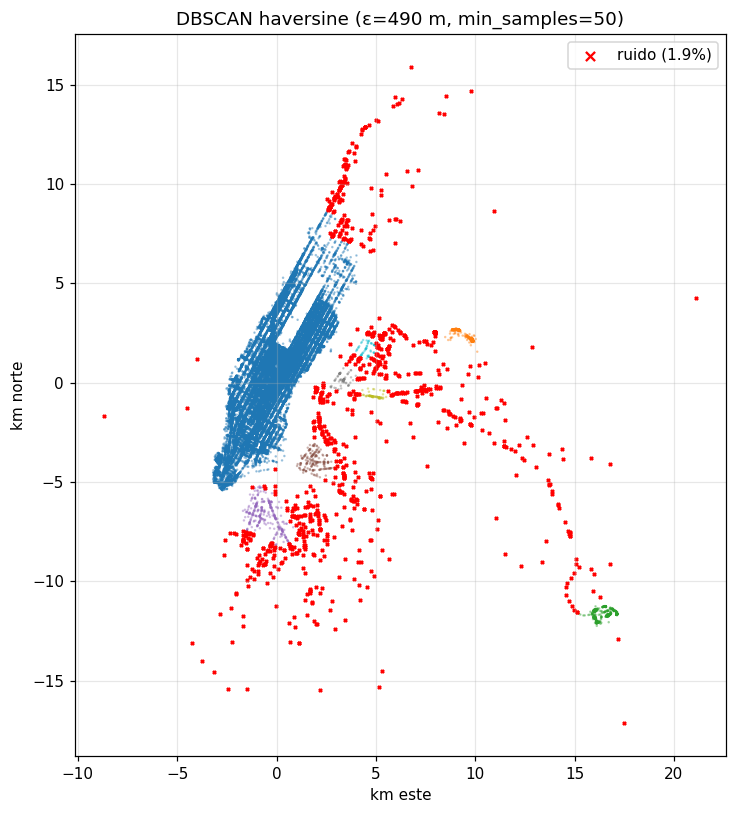

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ruido = df.db == -1
ax.scatter(df.px[~ruido], df.py[~ruido], c=df.db[~ruido], cmap="tab10", s=.4, alpha=.4)
ax.scatter(df.px[ruido], df.py[ruido], c="red", s=4, marker="x", label=f"ruido ({ruido.mean():.1%})")
ax.set_aspect("equal"); ax.legend(markerscale=3); ax.set_title(f"DBSCAN haversine (ε={EPS_M:.0f} m, min_samples={MIN_S})")
ax.set_xlabel("km este"); ax.set_ylabel("km norte"); plt.tight_layout(); plt.savefig("figuras/rol2_dbscan.png", bbox_inches="tight"); plt.show()

### A.4 Comparación de los tres métodos con métricas de validación
Las métricas se calculan en km (espacio proyectado). Para DBSCAN se reportan **sobre los puntos no-ruido** (el ruido no es un cluster). Silueta y Davies-Bouldin sobre submuestra de 10 000 puntos; el jerárquico sobre su submuestra de 5 000.

In [13]:
def metricas(Xm, lab, nombre, nota=""):
    s = silhouette_score(Xm, lab, sample_size=min(10000, len(Xm)), random_state=0)
    return [nombre, len(set(lab)), s, davies_bouldin_score(Xm, lab), calinski_harabasz_score(Xm, lab), nota]
nr = df.db.values >= 0
comp = pd.DataFrame([
    metricas(X, df.km.values, "K-means (K=4)", "50 000 puntos"),
    metricas(Xs, lab_w, "Jerárquico Ward (K=4)", "submuestra 5 000"),
    metricas(X[nr], df.db.values[nr], f"DBSCAN (ε={EPS_M:.0f} m)", f"sin ruido; ruido = {pct_ruido:.2f} %"),
], columns=["Método", "clusters", "silueta ↑", "Davies-Bouldin ↓", "Calinski-Harabasz ↑", "nota"])
print(comp.round(3).to_string(index=False))
ari_km_ward = adjusted_rand_score(km_sub, lab_w)
ari_km_db = adjusted_rand_score(df.km[nr], df.db[nr])
print(f"\nARI K-means vs Ward = {ari_km_ward:.3f} | ARI K-means vs DBSCAN (no ruido) = {ari_km_db:.3f}")
print("\nTabla cruzada K-means vs DBSCAN (% de la muestra):")
print((100 * pd.crosstab(df.km, df.db, normalize=True)).round(2).to_string())

               Método  clusters  silueta ↑  Davies-Bouldin ↓  Calinski-Harabasz ↑                      nota
        K-means (K=4)         4      0.491             0.504            68826.611             50 000 puntos
Jerárquico Ward (K=4)         4      0.483             0.481             6967.382          submuestra 5 000
     DBSCAN (ε=490 m)         8      0.137             0.502            11201.251 sin ruido; ruido = 1.88 %

ARI K-means vs Ward = 0.822 | ARI K-means vs DBSCAN (no ruido) = 0.155

Tabla cruzada K-means vs DBSCAN (% de la muestra):
db    -1      0     1     2     3     4     5     6     7
km                                                       
0   0.44  50.19  0.00  0.00  0.00  0.00  0.15  0.06  0.09
1   0.76  41.93  0.00  0.00  0.68  0.39  0.00  0.00  0.00
2   0.58   0.00  2.51  0.00  0.00  0.00  0.00  0.08  0.02
3   0.09   0.00  0.00  2.02  0.00  0.00  0.00  0.00  0.00


**Comparación final.**
- **K-means y Ward coinciden** (ARI 0.82) con silueta ≈ 0.48–0.49 y Davies-Bouldin ≈ 0.48–0.50: la partición en 4 macro-zonas es robusta al método.
- **DBSCAN** tiene silueta baja (0.137) *y aun así es útil*: la silueta premia grupos convexos y separados, y DBSCAN produce un cluster enorme y no convexo (toda Manhattan) junto a focos pequeños y vecinos. Su ARI con K-means es bajo (0.155) porque responde a otra pregunta: **densidad**, no cercanía a un centroide. Davies-Bouldin (0.502) es comparable a K-means.
- Uso recomendado: **K-means (K = 4) para planificar la flota por macro-zona** y **DBSCAN para identificar focos secundarios y el ruido**.

## Parte B — DBSCAN para detectar **viajes** atípicos
Un viaje es atípico si su combinación **distancia–duración** es rara (p. ej. 0.3 km en 40 min, o 15 km en 6 min). Trabajamos en el espacio estandarizado $(\log d, \log t)$: la escala log hace comparables viajes cortos y largos y la estandarización iguala las unidades. Se reutiliza el mismo protocolo: `min_samples = 50` y ε por k-distancia.

In [14]:
F = np.c_[np.log(df.dist_km), np.log(df.duracion_min)]
sc = StandardScaler().fit(F); Fz = sc.transform(F)
d50, _ = NearestNeighbors(n_neighbors=MIN_S).fit(Fz).kneighbors(Fz)
kd2 = np.sort(d50[:, -1]); j = kneedle_creciente(kd2); EPS_V = float(np.round(kd2[j], 3))
print(f"eps viajes (kneedle) = {EPS_V} (percentil {100 * j / len(kd2):.1f})")
dbv = DBSCAN(eps=EPS_V, min_samples=MIN_S).fit(Fz); df["ruido_viaje"] = dbv.labels_ == -1
print(f"Clusters: {dbv.labels_.max() + 1} | viajes ruido: {df.ruido_viaje.sum()} ({100 * df.ruido_viaje.mean():.2f} %)")

# Comparación con K-means en el mismo espacio: K-means NO tiene noción de ruido
kmv = KMeans(3, n_init=10, random_state=SEED).fit(Fz)
print(f"K-means (K=3) en el mismo espacio: silueta = {silhouette_score(Fz, kmv.labels_, sample_size=10000, random_state=0):.3f}; "
      f"asigna el 100 % de los viajes, incluidos los {df.ruido_viaje.sum()} atípicos, a algún grupo.")

eps viajes (kneedle) = 0.182 (percentil 96.9)


Clusters: 1 | viajes ruido: 747 (1.49 %)


K-means (K=3) en el mismo espacio: silueta = 0.422; asigna el 100 % de los viajes, incluidos los 747 atípicos, a algún grupo.


En el espacio de viajes DBSCAN encuentra **un único cluster denso** (la relación normal distancia–duración) y **747 viajes ruido (1.49 %)**. K-means, en cambio, obliga a cada viaje atípico a pertenecer a algún grupo, contaminando sus centroides: esta es la razón para usar DBSCAN en la detección de anomalías.

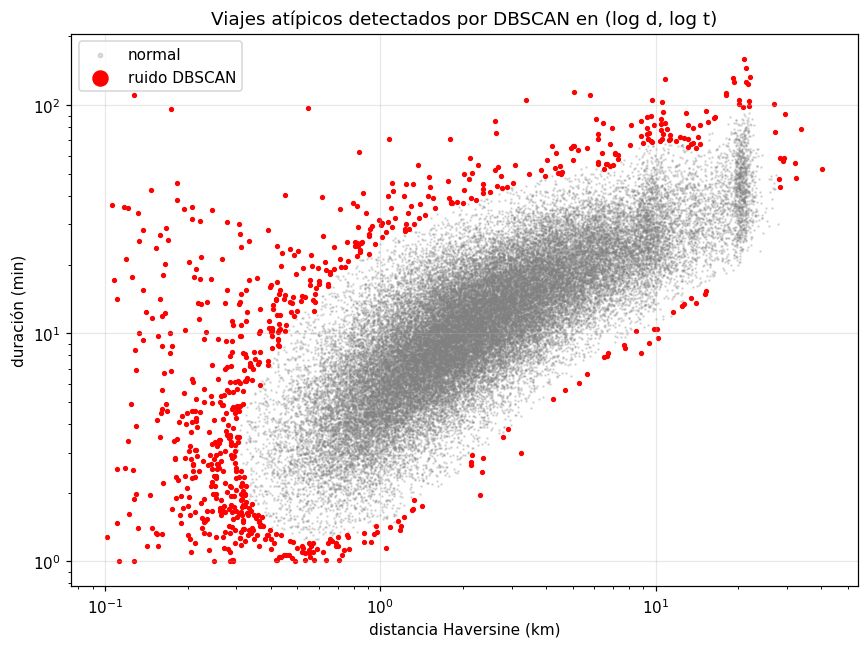

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df.dist_km[~df.ruido_viaje], df.duracion_min[~df.ruido_viaje], s=.5, alpha=.25, c="gray", label="normal")
ax.scatter(df.dist_km[df.ruido_viaje], df.duracion_min[df.ruido_viaje], s=6, c="red", label="ruido DBSCAN")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("distancia Haversine (km)"); ax.set_ylabel("duración (min)")
ax.set_title("Viajes atípicos detectados por DBSCAN en (log d, log t)"); ax.legend(markerscale=4)
plt.tight_layout(); plt.savefig("figuras/rol2_ruido_viajes.png", bbox_inches="tight"); plt.show()

In [16]:
rv = df[df.ruido_viaje]; nv = df[~df.ruido_viaje]
tipo = np.where(rv.vel_kmh < np.percentile(nv.vel_kmh, 5), "lento (posible taxímetro olvidado / trancón extremo)",
       np.where(rv.vel_kmh > np.percentile(nv.vel_kmh, 95), "rápido (autopista / posible error GPS)", "extremo en distancia (sobre todo muy corto) con velocidad normal"))
rv = rv.assign(tipo=tipo)
resumen_ruido = rv.groupby("tipo").agg(viajes=("id", "size"), dist_med=("dist_km", "median"), dur_med=("duracion_min", "median"),
                                      vel_med=("vel_kmh", "median"), pct_aeropuerto=("zona_pickup", lambda s: 100 * s.str.contains("Aeropuerto").mean()))
print(resumen_ruido.round(2).to_string())
print(f"\nVelocidad mediana: normales {nv.vel_kmh.median():.1f} km/h vs ruido {rv.vel_kmh.median():.1f} km/h")
print(f"Pickups en aeropuertos: normales {100 * nv.zona_pickup.str.contains('Aeropuerto').mean():.1f} % vs ruido {100 * rv.zona_pickup.str.contains('Aeropuerto').mean():.1f} %")
print(f"Recogidas en ruido espacial (Parte A) que además son viajes atípicos: {100 * rv.db.eq(-1).mean():.1f} % vs {100 * nv.db.eq(-1).mean():.1f} % en normales")

                                                                  viajes  dist_med  dur_med  vel_med  pct_aeropuerto
tipo                                                                                                                
extremo en distancia (sobre todo muy corto) con velocidad normal     252      0.33     1.85     9.80           15.87
lento (posible taxímetro olvidado / trancón extremo)                 417      0.34    13.75     2.34            1.68
rápido (autopista / posible error GPS)                                78      1.37     1.81    45.91           10.26

Velocidad mediana: normales 12.9 km/h vs ruido 4.7 km/h
Pickups en aeropuertos: normales 4.1 % vs ruido 7.4 %
Recogidas en ruido espacial (Parte A) que además son viajes atípicos: 2.9 % vs 1.9 % en normales


**Tipos de viajes atípicos y tratamiento operativo.**

| Tipo | Viajes | Perfil | Tratamiento propuesto para UrbanMove |
|---|---|---|---|
| **Lento** | 417 (0.83 %) | mediana 0.34 km en 13.8 min (2.3 km/h) | Posible taxímetro olvidado, espera con el viaje activo o error de GPS en el destino. **Auditar** y **excluir del entrenamiento de ETA/tarifa**; alerta automática si un viaje activo baja de ~3 km/h durante > 10 min. |
| **Extremo en distancia** | 252 (0.50 %) | sobre todo trayectos muy cortos (mediana 0.33 km en 1.9 min) | Probables cancelaciones o reubicaciones. Aplicar **tarifa mínima** y no contarlos como demanda real en los modelos de posicionamiento. |
| **Rápido** | 78 (0.16 %) | mediana 45.9 km/h | Autopistas nocturnas o saltos de GPS. Validar con la ruta; mantener si es plausible. |

La velocidad mediana del ruido es 4.7 km/h vs 12.9 km/h en viajes normales. Dejar estos viajes en los modelos sesga las estimaciones de duración (ver la brecha de Jensen del Rol 1).

In [17]:
# Zonas de recogida del ruido ESPACIAL (Parte A): ¿dónde está la demanda dispersa?
rz = df[df.db == -1]
print("Ruido espacial por zona del grid:\n", rz.zona_pickup.value_counts().head(8).to_string())
print(f"\nDistancia mediana: ruido espacial {rz.dist_km.median():.2f} km vs resto {df[df.db != -1].dist_km.median():.2f} km")
print(f"Duración mediana: ruido espacial {rz.duracion_min.median():.1f} min vs resto {df[df.db != -1].duracion_min.median():.1f} min")
print(f"% en madrugada: ruido espacial {100 * (rz.franja == 'Madrugada (0-5h)').mean():.1f} % vs resto {100 * (df[df.db != -1].franja == 'Madrugada (0-5h)').mean():.1f} %")

Ruido espacial por zona del grid:
 zona_pickup
Otras                   938
Z15 Aeropuerto JFK        1
Z08 Lenox Hill (UES)      1

Distancia mediana: ruido espacial 3.29 km vs resto 2.10 km
Duración mediana: ruido espacial 12.2 min vs resto 11.1 min
% en madrugada: ruido espacial 31.7 % vs resto 11.6 %


**Tratamiento de las zonas atípicas (ruido espacial).** Las 940 recogidas ruido (1.88 %) están casi todas en la zona `Otras` (fuera del núcleo) y son **viajes más largos** (mediana 3.29 km vs 2.10 km) con **2.7 veces más peso en la madrugada** (31.7 % vs 11.6 %). Posicionar conductores ahí sería sobre-ofertar; la recomendación es **despacho bajo demanda** desde el borde del cluster más cercano, con un **recargo por desplazamiento** o un ETA garantizado más largo, en lugar de flota dedicada.

In [18]:
res = {
    "K_elegido": K, "K_codo_kneedle": K_codo, "curva_K": curva[["inercia", "silueta", "davies_bouldin"]].round(4).reset_index().to_dict("list"),
    "comparacion": comp.drop(columns="nota").round(4).to_dict("records"),
    "jerarquico_enlaces": tabla_jer.drop(columns=["tamaños", "seg"]).round(4).to_dict("records"),
    "ARI_km_ward": ari_km_ward, "ARI_km_dbscan": ari_km_db,
    "dbscan_eps_m": EPS_M, "dbscan_min_samples": MIN_S, "dbscan_clusters": int(n_cl), "dbscan_pct_ruido": pct_ruido,
    "perfil_kmeans": perfil_km.reset_index().round(3).to_dict("records"),
    "perfil_dbscan": perfil_db.reset_index().round(3).to_dict("records"),
    "viajes_eps": EPS_V, "viajes_pct_ruido": 100 * df.ruido_viaje.mean(), "viajes_n_ruido": int(df.ruido_viaje.sum()),
    "ruido_viajes_tipos": resumen_ruido.reset_index().round(3).to_dict("records"),
    "ruido_espacial_dist_med": float(rz.dist_km.median()), "resto_dist_med": float(df[df.db != -1].dist_km.median()),
    "ruido_espacial_top_zonas": rz.zona_pickup.value_counts().head(5).to_dict(),
}
utils.guardar_resultados("rol2.json", res)
df[["id", "km", "db", "ruido_viaje"]].to_csv("resultados/rol2_etiquetas.csv", index=False)
print("Guardado resultados/rol2.json y resultados/rol2_etiquetas.csv")

Guardado resultados/rol2.json y resultados/rol2_etiquetas.csv
